# Route pricing analysis; Which freight routes are billed below the carrier's typical price per mile, and what is raising them worth per year? Data: output of route_pricing.sql (one row per route)

In [1]:
import pandas as pd

df = pd.read_csv("route_pricing.csv")
df.head()

,route_id,origin_city,destination_city,typical_distance_miles,base_rate_per_mile,num_loads,total_revenue,billed_per_mile
0,RTE00037,Las Vegas,New York,2561,1.52,1477,5.770648e+06,1.525578
1,RTE00043,Charlotte,Denver,1559,1.55,1500,3.616131e+06,1.546346
2,RTE00010,New York,Philadelphia,92,1.61,1468,2.175730e+05,1.610984
3,RTE00052,Memphis,Minneapolis,804,1.63,1490,1.950967e+06,1.628574
4,RTE00025,Miami,Seattle,3141,1.65,1450,7.523007e+06,1.651793


In [3]:
df.shape

(58, 8)

## Step 1: Finding the fair price; The 25th percentile is the price that a quarter of routes fall below. I use it as the fair price.

In [4]:
df["billed_per_mile"].describe()

count    58.000000
mean      2.196223
std       0.368235
min       1.525578
25%       1.902577
50%       2.225068
75%       2.483619
max       2.782304
Name: billed_per_mile, dtype: float64

## Step 2: Flagging the routes below the fair price

In [5]:
fair_price = df["billed_per_mile"].quantile(0.25)
flagged = df[df["billed_per_mile"] < fair_price]
len(flagged)

15

In [6]:
flagged[["origin_city", "destination_city", "billed_per_mile"]]

,origin_city,destination_city,billed_per_mile
0,Las Vegas,New York,1.525578
1,Charlotte,Denver,1.546346
2,New York,Philadelphia,1.610984
3,Memphis,Minneapolis,1.628574
4,Miami,Seattle,1.651793
5,New York,Columbus,1.683365
6,Las Vegas,Dallas,1.688688
7,Atlanta,Chicago,1.699647
8,Phoenix,Denver,1.699652
9,Miami,Denver,1.717537


In [7]:
flagged = flagged.copy()
flagged["extra_per_mile"] = fair_price - flagged["billed_per_mile"]
flagged["miles_driven"] = flagged["num_loads"] * flagged["typical_distance_miles"]
flagged["gain_total"] = flagged["extra_per_mile"] * flagged["miles_driven"]
flagged["gain_per_year"] = flagged["gain_total"] / 3

flagged[["origin_city", "destination_city", "extra_per_mile", "miles_driven", "gain_per_year"]].sort_values("gain_per_year", ascending=False)

,origin_city,destination_city,extra_per_mile,miles_driven,gain_per_year
0,Las Vegas,New York,0.376999,3782597,475345.340706
4,Miami,Seattle,0.250785,4554450,380728.941843
1,Charlotte,Denver,0.356231,2338500,277682.084377
9,Miami,Denver,0.185041,2856960,176218.018944
10,Houston,Seattle,0.131487,3225420,141367.392802
6,Las Vegas,Dallas,0.213889,1770989,126265.008201
3,Memphis,Minneapolis,0.274003,1197960,109414.894931
7,Atlanta,Chicago,0.202930,985712,66676.881365
8,Phoenix,Denver,0.202925,983926,66554.456340
12,Chicago,Portland,0.061421,2942803,60250.093738


## Step 3: Extra revenue per route; Extra per mile × miles driven ÷ 3 years (the data covers 2022 to 2024).

In [8]:
flagged["gain_per_year"].sum()

np.float64(2062632.2699404075)

## Step 4: Chart; Routes sorted by price. Red bars are below the fair price.

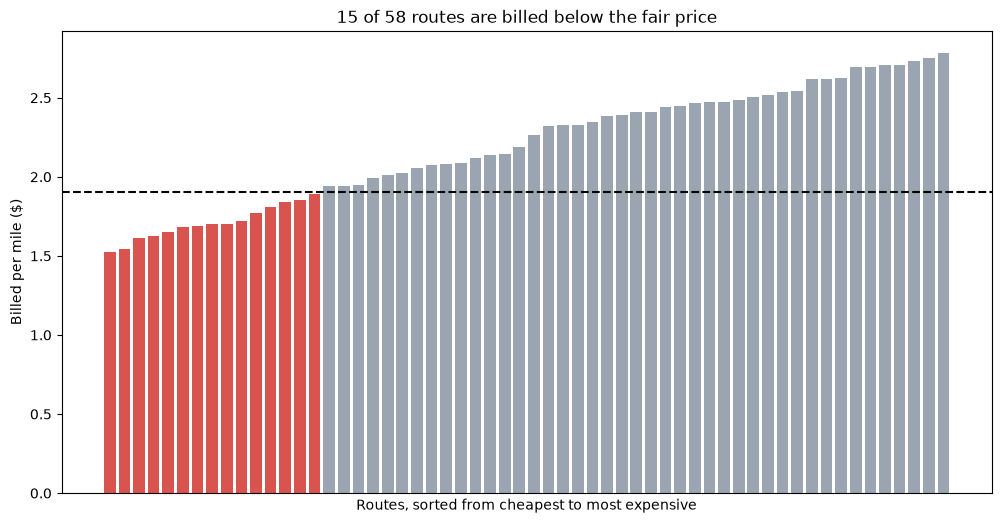

In [13]:
import matplotlib.pyplot as plt

plot_df = df.sort_values("billed_per_mile").reset_index(drop=True)
colors = ["#d9534f" if p < fair_price else "#9aa5b1" for p in plot_df["billed_per_mile"]]

plt.figure(figsize=(12, 6))
plt.bar(range(len(plot_df)), plot_df["billed_per_mile"], color=colors)
plt.axhline(fair_price, color="black", linestyle="--")
plt.title("15 of 58 routes are billed below the fair price")
plt.xlabel("Routes, sorted from cheapest to most expensive")
plt.ylabel("Billed per mile ($)")
plt.xticks([])
plt.savefig("price_per_mile_by_route.png", dpi=150)
plt.show()

## Step 5: Saving the results for Excel and Power BI

In [14]:
flagged.to_csv("flagged_routes.csv", index=False)